In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.sparse import hstack
import joblib

In [2]:
df = pd.read_csv("CFO_001_customer_churn_clean.csv")

In [3]:
df.head(10)

,customer_id,age,tenure_months,monthly_charges,support_calls,monthly_data_gb,contract_type,payment_method,internet_service,paperless_billing,churn
0,C00001,23,59,51.67,0,148.0,Two year,Electronic check,DSL,Yes,0
1,C00002,62,54,88.34,1,60.9,Month-to-month,Bank transfer,Fiber,Yes,1
2,C00003,55,41,68.76,1,97.6,Month-to-month,Bank transfer,No internet,Yes,1
3,C00004,43,64,61.78,0,76.8,Month-to-month,Bank transfer,DSL,No,0
4,C00005,42,10,65.66,2,187.3,Month-to-month,Credit card,DSL,Yes,0
5,C00006,66,67,72.91,0,153.3,Month-to-month,Bank transfer,No internet,No,0
6,C00007,22,62,81.57,0,36.3,Month-to-month,Credit card,DSL,Yes,0
7,C00008,57,37,46.01,1,62.5,One year,Electronic check,DSL,Yes,0
8,C00009,29,53,45.09,2,115.0,Two year,Electronic check,No internet,No,0
9,C00010,23,38,92.30,2,102.0,Month-to-month,Mailed check,Fiber,No,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1000 non-null   str    
 1   age                1000 non-null   int64  
 2   tenure_months      1000 non-null   int64  
 3   monthly_charges    1000 non-null   float64
 4   support_calls      1000 non-null   int64  
 5   monthly_data_gb    1000 non-null   float64
 6   contract_type      1000 non-null   str    
 7   payment_method     1000 non-null   str    
 8   internet_service   1000 non-null   str    
 9   paperless_billing  1000 non-null   str    
 10  churn              1000 non-null   int64  
dtypes: float64(2), int64(4), str(5)
memory usage: 86.1 KB


In [5]:
X = df.drop(["churn", "customer_id"], axis=1)

In [6]:
numerical_col = X.select_dtypes(include="number").columns
categorical_col = X.select_dtypes(exclude="number").columns

In [7]:
scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

In [8]:
X_scaled = scaler.fit_transform(X[numerical_col])
X_encoded = encoder.fit_transform(X[categorical_col])

In [9]:
X_processed = np.hstack([X_scaled, X_encoded])

In [10]:
print(X_processed.shape)

(1000, 17)


In [11]:
model = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

In [12]:
labels = model.fit_predict(X_processed)

In [13]:
df["cluster_3"] = labels

In [14]:
print(df[["cluster_3", "customer_id"]].head(10))

   cluster_3 customer_id
0          2      C00001
1          0      C00002
2          0      C00003
3          2      C00004
4          1      C00005
5          0      C00006
6          2      C00007
7          0      C00008
8          2      C00009
9          2      C00010


In [15]:
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    model.fit_predict(X_processed)
    wcss.append(model.inertia_)

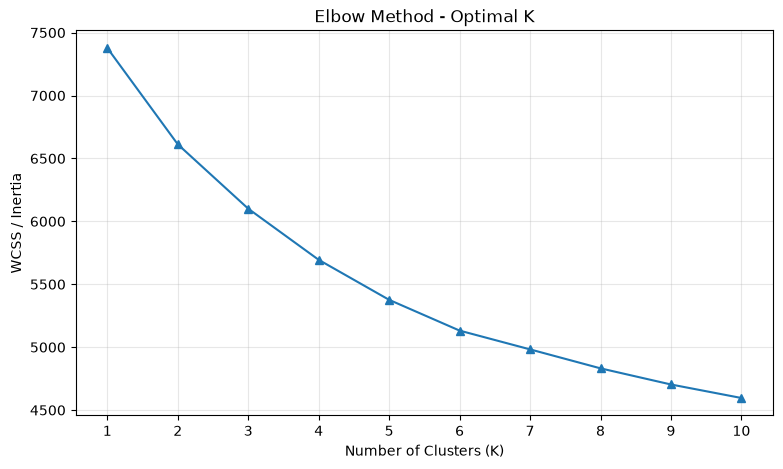

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="^",
)

plt.title("Elbow Method - Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

In [17]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    labels = model.fit_predict(X_processed)
    score = silhouette_score(
        X_processed,
        labels
    )
    silhouette_scores.append(score)

    print(f"for K = {k}, scores: {score:.4f}")
    

for K = 2, scores: 0.1015
for K = 3, scores: 0.0987
for K = 4, scores: 0.0945
for K = 5, scores: 0.0951
for K = 6, scores: 0.0946
for K = 7, scores: 0.0879
for K = 8, scores: 0.0878
for K = 9, scores: 0.0879
for K = 10, scores: 0.0848


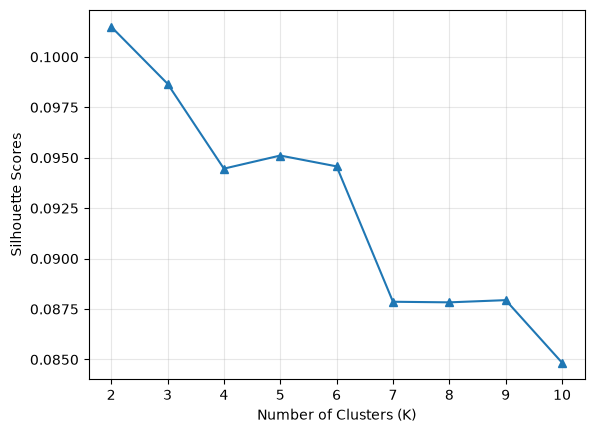

In [18]:
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="^"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Scores")
plt.grid(alpha=0.3)
plt.xticks(range(2, 11))
plt.show()

In [19]:
k_means2 = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels_2 = k_means2.fit_predict(X_processed)

In [20]:
k_means4 = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels_4 = k_means4.fit_predict(X_processed)

In [21]:
for k, name, label in [
    (2, k_means2, labels_2),
    (4, k_means4, labels_4)
]:
    print(f"\nFor cluster K values: {k}")

    print(f"Silhouette_score: {silhouette_score(X_processed,label)}")

    print(f"davies_bouldin_score: {davies_bouldin_score(X_processed,label)}")

    print(f"calinski_harabasz_score: {calinski_harabasz_score(X_processed,label)}")


For cluster K values: 2
Silhouette_score: 0.10149631655851836
davies_bouldin_score: 2.874249784379511
calinski_harabasz_score: 115.55068202468955

For cluster K values: 4
Silhouette_score: 0.0944602218926958
davies_bouldin_score: 2.2934016168302263
calinski_harabasz_score: 98.156348778158


In [22]:
df["cluster_2"] = labels_2
df["cluster_4"] = labels_4

In [23]:
features = [
    "age",
    "tenure_months",
    "monthly_charges",
    "support_calls",
    "monthly_data_gb",
    "churn"
]

In [24]:
print("CUSTOMER SEGMENTS: K = 2")

print(
    df.groupby("cluster_2")[features]
    .mean()
    .round(2)
)

CUSTOMER SEGMENTS: K = 2
             age  tenure_months  monthly_charges  support_calls  \
cluster_2                                                         
0          59.38          33.17            68.72           1.50   
1          31.46          39.71            63.81           1.42   

           monthly_data_gb  churn  
cluster_2                          
0                   120.55   0.45  
1                   117.60   0.35  


In [25]:
print("\nCUSTOMER SEGMENTS: K = 4")

print(
    df.groupby("cluster_4")[features]
    .mean()
    .round(2)
)


CUSTOMER SEGMENTS: K = 4
             age  tenure_months  monthly_charges  support_calls  \
cluster_4                                                         
0          29.52          44.36            68.84           0.82   
1          59.97          52.86            75.42           1.16   
2          53.38          15.50            63.49           1.10   
3          41.02          37.47            56.56           3.28   

           monthly_data_gb  churn  
cluster_4                          
0                   106.88   0.35  
1                   128.94   0.39  
2                   122.10   0.42  
3                   119.52   0.48  


In [26]:
print("K 2:")
print(df["cluster_2"].value_counts().sort_index())

K 2:
cluster_2
0    527
1    473
Name: count, dtype: int64


In [27]:
print("K 4:")
print(df["cluster_4"].value_counts().sort_index())

K 4:
cluster_4
0    267
1    236
2    304
3    193
Name: count, dtype: int64


In [28]:
seeds = [0, 10, 21, 42, 100]

for k in [2, 4]:
    all_labels = []

    for seed in seeds:
        exp_kmeans = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            random_state=seed
        )

        label = exp_kmeans.fit_predict(X_processed)

        all_labels.append(label)

    ari_scores = []
    for i in range(len(all_labels)):
        for j in range(i+1, len(all_labels)):
            ari_score = adjusted_rand_score(all_labels[i], all_labels[j])

            ari_scores.append(ari_score)

    print(f"\nK = {k}")
    print("Average Stability:", np.mean(ari_scores).round(4))
    print("Minimum Stability:", np.min(ari_scores).round(4))
            


K = 2
Average Stability: 0.9841
Minimum Stability: 0.9604

K = 4
Average Stability: 0.8134
Minimum Stability: 0.7152


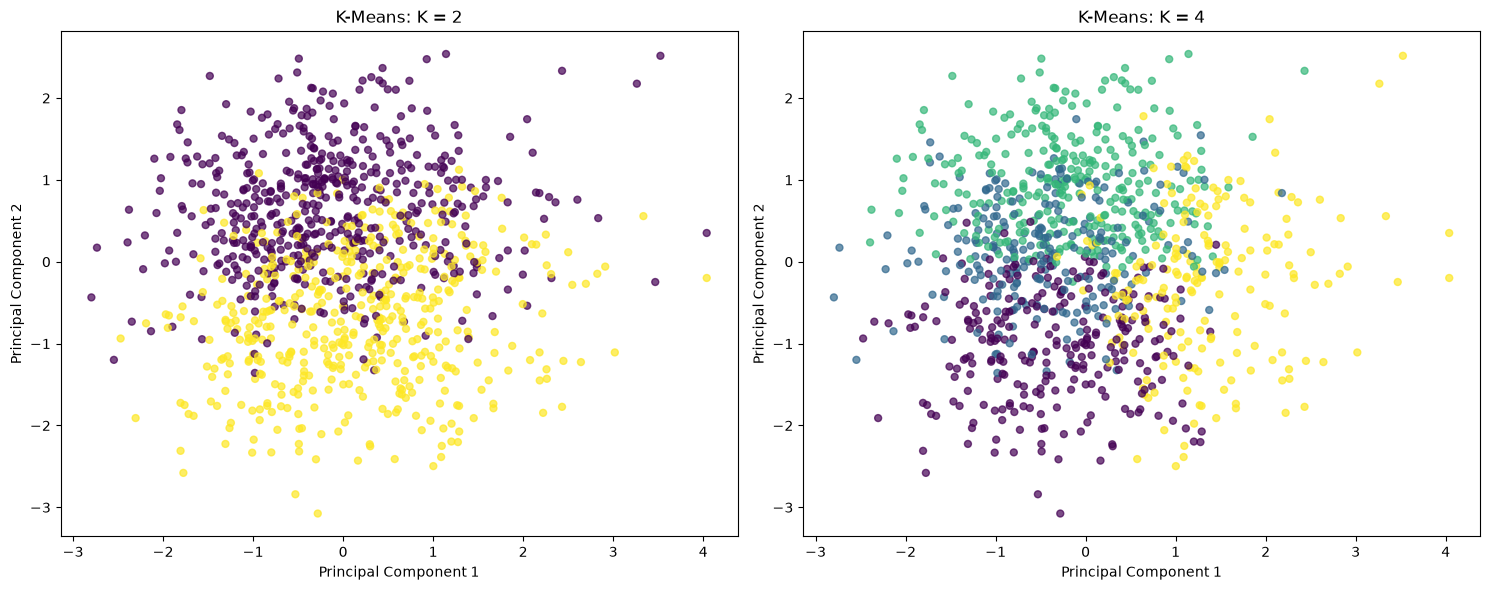

In [29]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_processed)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# K = 2
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_2,
    cmap="viridis",
    s=25,
    alpha=0.7
)

axes[0].set_title("K-Means: K = 2")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# K = 4
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_4,
    cmap="viridis",
    s=25,
    alpha=0.7
)

axes[1].set_title("K-Means: K = 4")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [30]:
cluster_profile = df.groupby("cluster_2").agg({
    "age": "mean",
    "tenure_months": "mean",
    "monthly_charges": "mean",
    "support_calls": "mean",
    "monthly_data_gb": "mean",
    "churn": "mean"
})

print(cluster_profile.round(2))

             age  tenure_months  monthly_charges  support_calls  \
cluster_2                                                         
0          59.38          33.17            68.72           1.50   
1          31.46          39.71            63.81           1.42   

           monthly_data_gb  churn  
cluster_2                          
0                   120.55   0.45  
1                   117.60   0.35  


In [31]:
print("Customer count per cluster:")
print(df["cluster_2"].value_counts())

print("\nPercentage distribution:")
print(
    (df["cluster_2"].value_counts(normalize=True) * 100).round(2)
)

Customer count per cluster:
cluster_2
0    527
1    473
Name: count, dtype: int64

Percentage distribution:
cluster_2
0    52.7
1    47.3
Name: proportion, dtype: float64


In [32]:
print("Clusters centroids: ")
print(k_means2.cluster_centers_)

Clusters centroids: 
[[ 0.80327914 -0.14743303  0.10530393  0.03079806  0.03658775  0.5597723
   0.25426945  0.18595825  0.25616698  0.25616698  0.25806452  0.22960152
   0.31119545  0.53510436  0.15370019  0.29222011  0.70777989]
 [-0.89498543  0.16426471 -0.11732594 -0.03431411 -0.04076478  0.54122622
   0.25792812  0.20084567  0.26215645  0.23044397  0.26215645  0.24524313
   0.42283298  0.41014799  0.16701903  0.30655391  0.69344609]]


In [33]:
print("Cluster Labels:")
print(k_means2.labels_[:10])

Cluster Labels:
[1 0 0 1 0 0 1 0 1 1]


In [34]:
joblib.dump(
    k_means2,
    "cfo_001_cluster.joblib"
)

['cfo_001_cluster.joblib']

In [35]:
df.head()

,customer_id,age,tenure_months,monthly_charges,support_calls,monthly_data_gb,contract_type,payment_method,internet_service,paperless_billing,churn,cluster_3,cluster_2,cluster_4
0,C00001,23,59,51.67,0,148.0,Two year,Electronic check,DSL,Yes,0,2,1,0
1,C00002,62,54,88.34,1,60.9,Month-to-month,Bank transfer,Fiber,Yes,1,0,0,1
2,C00003,55,41,68.76,1,97.6,Month-to-month,Bank transfer,No internet,Yes,1,0,0,1
3,C00004,43,64,61.78,0,76.8,Month-to-month,Bank transfer,DSL,No,0,2,1,0
4,C00005,42,10,65.66,2,187.3,Month-to-month,Credit card,DSL,Yes,0,1,0,2


In [36]:
AC_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)
new_label = AC_model.fit_predict(X_processed)
Z = linkage(X_processed, method="ward")
df["cluster"] = new_label

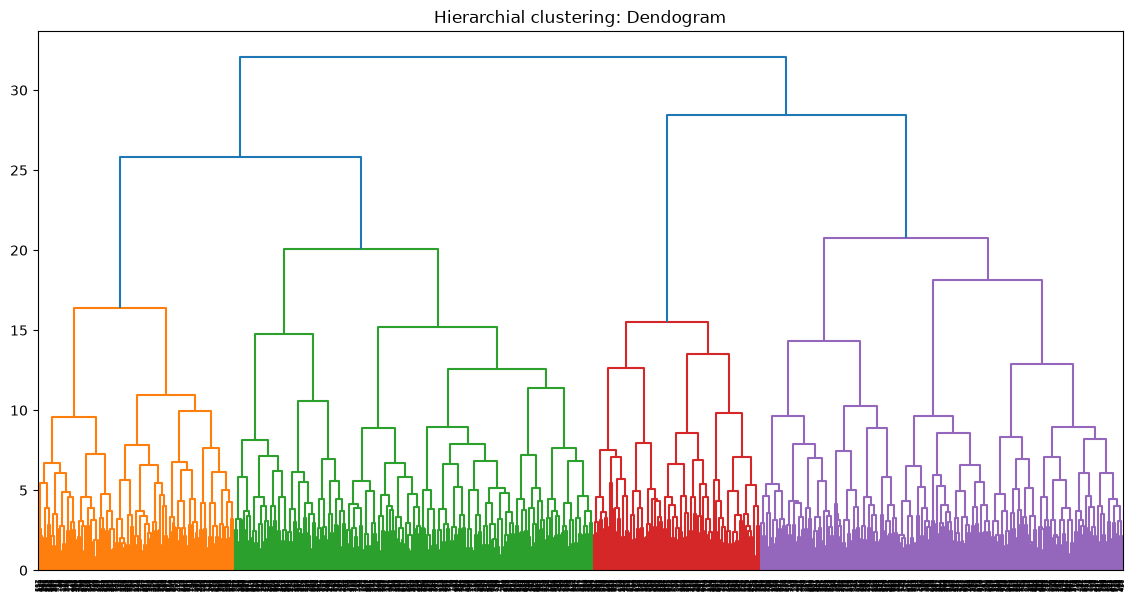

In [37]:
plt.figure(figsize=(14, 7))
dendrogram(Z)
plt.title("Hierarchial clustering: Dendogram")
plt.show()

In [38]:
cluster_label = fcluster(
    Z,
    t=23,
    criterion="distance"
)

df["hierarchial_cluster"] = cluster_label

print("No. of cluster: ", len(set(cluster_label)))

cluster_label_2 = fcluster(
    Z,
    t=27,
    criterion="distance"
)

df["hierarchial_cluster_2"] = cluster_label_2

print("No. of cluster: ", len(set(cluster_label_2)))

No. of cluster:  4
No. of cluster:  3


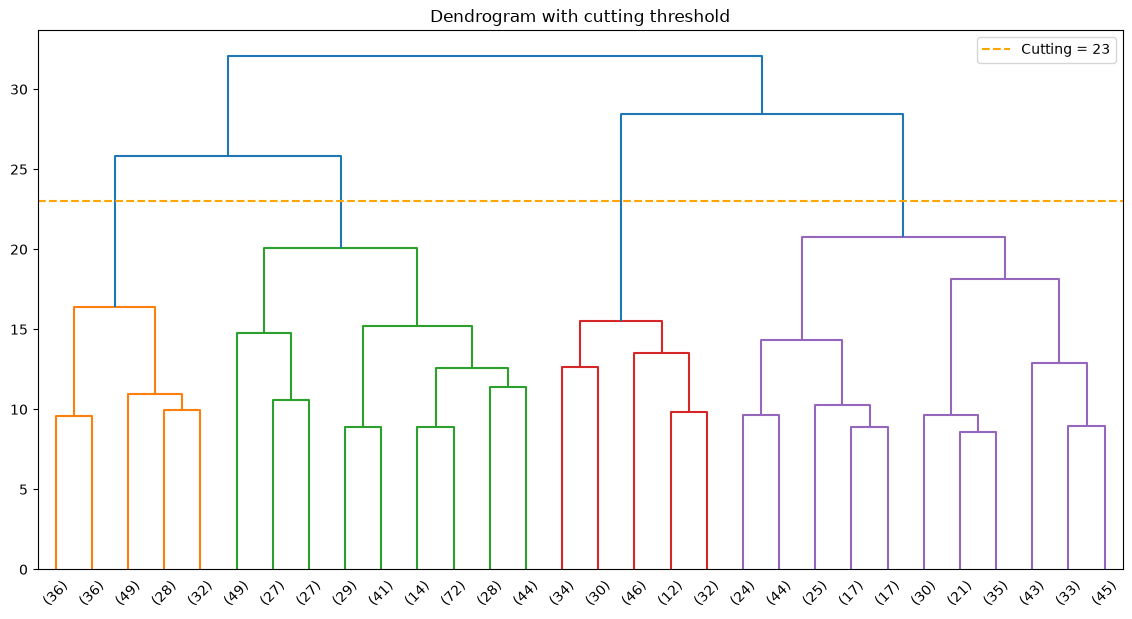

In [39]:
plt.figure(figsize=(14, 7))
dendrogram(Z, truncate_mode="lastp", p=30)

plt.axhline(
    y=23,
    color="orange",
    linestyle="--",
    label="Cutting = 23"
)
plt.legend()
plt.title("Dendrogram with cutting threshold")
plt.show()

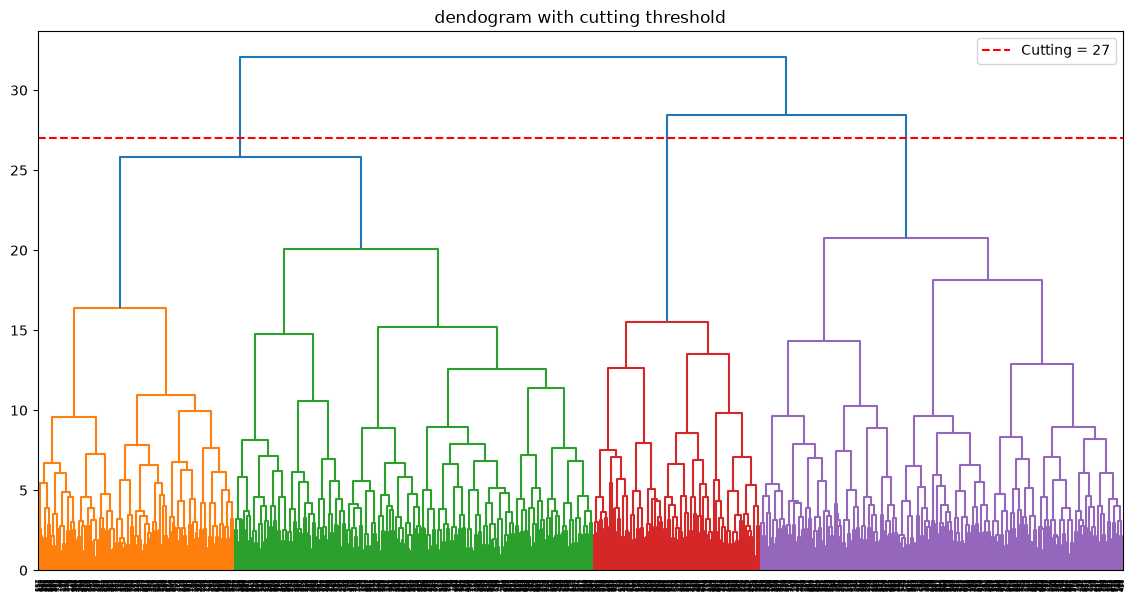

In [40]:
plt.figure(figsize=(14, 7))
dendrogram(Z)

plt.axhline(
    y=27,
    color="red",
    linestyle="--",
    label="Cutting = 27"
)

plt.legend()
plt.title("dendogram with cutting threshold")
plt.show()

In [41]:
for cluster, label in[
    (4, cluster_label),
    (3, cluster_label_2)
]:
    print("\nfor clusters: ", cluster)
    print("Silhouette_score: ", silhouette_score(X_processed, label))
    print("davies_bouldin_score: ", davies_bouldin_score(X_processed, label))
    print("calinski_harabasz_score: ", calinski_harabasz_score(X_processed, label))


for clusters:  4
Silhouette_score:  0.05342906282407166
davies_bouldin_score:  2.803848151543701
calinski_harabasz_score:  67.84462832059783

for clusters:  3
Silhouette_score:  0.0651727356452685
davies_bouldin_score:  3.067906912485635
calinski_harabasz_score:  70.93439147273632


In [42]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_label = hierarchical_model.fit_predict(X_processed)

df["hierarchical_4"] = hierarchical_label

print("\nfor clusters: ", cluster)
print("Silhouette_score: ", silhouette_score(X_processed, hierarchical_label))
print("davies_bouldin_score: ", davies_bouldin_score(X_processed, hierarchical_label))
print("calinski_harabasz_score: ", calinski_harabasz_score(X_processed, hierarchical_label))


for clusters:  3
Silhouette_score:  0.0651727356452685
davies_bouldin_score:  3.067906912485635
calinski_harabasz_score:  70.93439147273632


In [43]:
joblib.dump(
    hierarchical_model,
    "cfo_001_hierarchical.joblib"
)

['cfo_001_hierarchical.joblib']

In [48]:
db_model = DBSCAN(eps=0.5, min_samples=5)
db_label = db_model.fit_predict(X_processed)
df["db_label"] = db_label
mask = db_label != -1

In [50]:
if(len(set(db_label[mask]))) >= 2:
    print(f"\nSilhouette score: {silhouette_score(X_processed[mask], db_label[mask])}")
    print(f"davies_bouldin score: {davies_bouldin_score(X_processed[mask], db_label[mask])}")
    print(f"calinski_harabasz score: {calinski_harabasz(X_processed[mask], db_label[mask])}")
else:
    print("Not enough clusters to make noise")

Not enough clusters to make noise


In [53]:
# DBSCAN Diagnostic tool:

unique_labels, counts = np.unique(
    db_label,
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    print(f"Cluster {unique_labels} : {count} points")

print("Total clusters (excluding noise): ", len(set(db_label) - {-1}))

print("Noise points: ", np.sum(db_label == -1))

Cluster [-1] : 1000 points
Total clusters (excluding noise):  0
Noise points:  1000


In [71]:
for epsilon in np.arange(0.1, 3.1, 0.2):
    trial_db = DBSCAN(eps=epsilon, min_samples=5)

    trial_label = trial_db.fit_predict(X_processed)

#    mask = trial_label != -1

    print(f"\nfor eps= {epsilon}")
    print("No of clusters (excluding noise): ", len(set(trial_label) - {-1}))
    print("Noise points: ", np.sum(trial_label == -1))

    if(epsilon == 1.9000000000000004):
        unique_label, counts = np.unique(
            trial_label,
            return_counts = True
        )
        for label, count in zip(unique_label, counts):
            print(f"\nCluster {label} : {count} counts")


for eps= 0.1
No of clusters (excluding noise):  0
Noise points:  1000

for eps= 0.30000000000000004
No of clusters (excluding noise):  0
Noise points:  1000

for eps= 0.5000000000000001
No of clusters (excluding noise):  0
Noise points:  1000

for eps= 0.7000000000000002
No of clusters (excluding noise):  0
Noise points:  1000

for eps= 0.9000000000000001
No of clusters (excluding noise):  0
Noise points:  1000

for eps= 1.1
No of clusters (excluding noise):  1
Noise points:  995

for eps= 1.3000000000000003
No of clusters (excluding noise):  12
Noise points:  914

for eps= 1.5000000000000002
No of clusters (excluding noise):  10
Noise points:  789

for eps= 1.7000000000000004
No of clusters (excluding noise):  4
Noise points:  477

for eps= 1.9000000000000004
No of clusters (excluding noise):  2
Noise points:  186

Cluster -1 : 186 counts

Cluster 0 : 811 counts

Cluster 1 : 3 counts

for eps= 2.1000000000000005
No of clusters (excluding noise):  1
Noise points:  52

for eps= 2.30000

In [75]:
for ep in np.arange(0.1, 3, 0.1):

    model = DBSCAN(eps= ep, min_samples=5)

    model_label = model.fit_predict(X_processed)

    print(f"\nfor epsilon = {ep}")
    unique_labels, counts = np.unique(
        model_label,
        return_counts=True
    )
    for label, count in zip(unique_labels, counts):
        print(f"\nCluster {label}: {count} points")


for epsilon = 0.1

Cluster -1: 1000 points

for epsilon = 0.2

Cluster -1: 1000 points

for epsilon = 0.30000000000000004

Cluster -1: 1000 points

for epsilon = 0.4

Cluster -1: 1000 points

for epsilon = 0.5

Cluster -1: 1000 points

for epsilon = 0.6000000000000001

Cluster -1: 1000 points

for epsilon = 0.7000000000000001

Cluster -1: 1000 points

for epsilon = 0.8

Cluster -1: 1000 points

for epsilon = 0.9

Cluster -1: 1000 points

for epsilon = 1.0

Cluster -1: 1000 points

for epsilon = 1.1

Cluster -1: 995 points

Cluster 0: 5 points

for epsilon = 1.2000000000000002

Cluster -1: 948 points

Cluster 0: 5 points

Cluster 1: 6 points

Cluster 2: 7 points

Cluster 3: 7 points

Cluster 4: 5 points

Cluster 5: 4 points

Cluster 6: 5 points

Cluster 7: 4 points

Cluster 8: 4 points

Cluster 9: 5 points

for epsilon = 1.3

Cluster -1: 914 points

Cluster 0: 13 points

Cluster 1: 6 points

Cluster 2: 7 points

Cluster 3: 8 points

Cluster 4: 5 points

Cluster 5: 6 points

Cluster 6: 